# Lab 3: Clustering Analysis Using K-Means and K-Medoids Algorithms

**Student:** Xhon Pelushi  
**Course:** MSCS-634-B01 — Advanced Big Data and Data Mining  
**University:** University of the Cumberlands  
**Date:** November 2026

---
## Step 1: Load and Prepare the Dataset

We use the Wine Dataset from scikit-learn (178 samples, 3 classes, 13 features) and apply z-score standardization so that all features contribute equally to distance calculations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
%matplotlib inline

In [2]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = wine.target

print(f'Dataset shape: {X.shape}')
print(f'Number of classes: {len(np.unique(y_true))}')
print(f'\nClass distribution:')
print(pd.Series(y_true).value_counts().sort_index())
X.head()

Dataset shape: (178, 13)
Number of classes: 3

Class distribution:
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(f'Scaled data shape: {X_scaled.shape}')
print(f'Mean of first feature after scaling: {X_scaled[:, 0].mean():.6f}')
print(f'Std of first feature after scaling:  {X_scaled[:, 0].std():.6f}')

Scaled data shape: (178, 13)
Mean of first feature after scaling: -0.000000
Std of first feature after scaling:  1.000000


In [4]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(f'Explained variance ratio: {pca.explained_variance_ratio_}')
print(f'Total variance explained: {sum(pca.explained_variance_ratio_):.4f}')

Explained variance ratio: [0.36198848 0.1920749 ]
Total variance explained: 0.5541


---
## Step 2: K-Means Clustering

K-Means partitions data by minimizing the sum of squared distances from each point to its assigned centroid. We use k=3 to match the known number of wine classes.

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

kmeans_sil = silhouette_score(X_scaled, kmeans_labels)
kmeans_ari = adjusted_rand_score(y_true, kmeans_labels)

print('K-Means Results (k=3):')
print(f'  Silhouette Score: {kmeans_sil:.4f}')
print(f'  Adjusted Rand Index: {kmeans_ari:.4f}')
print(f'  Cluster sizes: {np.bincount(kmeans_labels)}')

K-Means Results (k=3):
  Silhouette Score: 0.2849
  Adjusted Rand Index: 0.8975
  Cluster sizes: [65 51 62]


---
## Step 3: K-Medoids Clustering

K-Medoids is similar to K-Means but uses actual data points (medoids) as cluster centers instead of computed centroids. This makes it more robust to outliers.

In [6]:
def kmedoids_cluster(X, k, max_iter=300, random_state=42):
    rng = np.random.RandomState(random_state)
    n = X.shape[0]
    dist = pairwise_distances(X)
    medoid_idx = rng.choice(n, k, replace=False)

    for _ in range(max_iter):
        labels = np.argmin(dist[:, medoid_idx], axis=1)
        new_medoids = np.empty(k, dtype=int)
        for c in range(k):
            members = np.where(labels == c)[0]
            costs = dist[np.ix_(members, members)].sum(axis=1)
            new_medoids[c] = members[np.argmin(costs)]
        if np.array_equal(new_medoids, medoid_idx):
            break
        medoid_idx = new_medoids

    labels = np.argmin(dist[:, medoid_idx], axis=1)
    centers = X[medoid_idx]
    return labels, centers, medoid_idx

In [7]:
kmedoids_labels, kmedoids_centers, medoid_indices = kmedoids_cluster(X_scaled, k=3)

kmedoids_sil = silhouette_score(X_scaled, kmedoids_labels)
kmedoids_ari = adjusted_rand_score(y_true, kmedoids_labels)

print('K-Medoids Results (k=3):')
print(f'  Silhouette Score: {kmedoids_sil:.4f}')
print(f'  Adjusted Rand Index: {kmedoids_ari:.4f}')
print(f'  Cluster sizes: {np.bincount(kmedoids_labels)}')
print(f'  Medoid indices: {medoid_indices}')

K-Medoids Results (k=3):
  Silhouette Score: 0.1548
  Adjusted Rand Index: 0.3413
  Cluster sizes: [89 24 65]
  Medoid indices: [ 35  43 163]


---
## Step 4: Visualize and Compare Results

We project the data to 2D using PCA and display side-by-side scatter plots for both algorithms, marking the centroids and medoids.

### 4.1 Side-by-Side Cluster Visualization

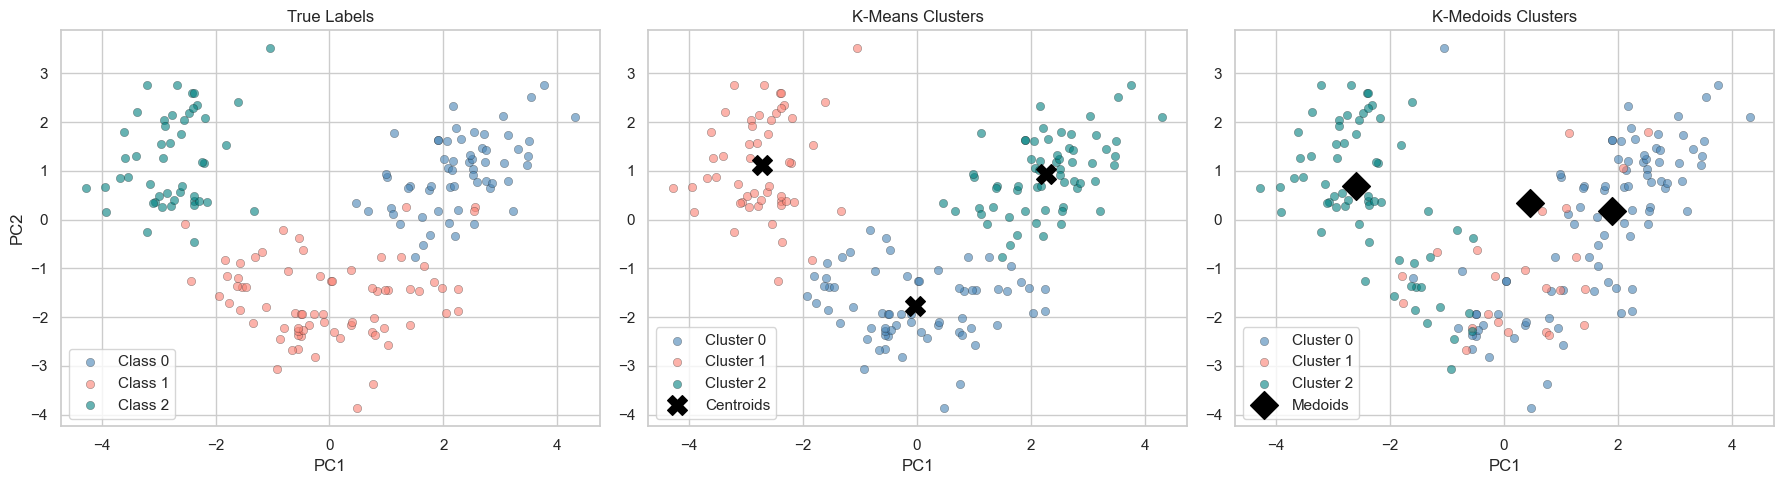

In [8]:
kmeans_centers_pca = pca.transform(kmeans.cluster_centers_)
kmedoids_centers_pca = pca.transform(kmedoids_centers)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['steelblue', 'salmon', 'teal']

for c in range(3):
    mask = y_true == c
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c=colors[c],
                    label=f'Class {c}', alpha=0.6, edgecolors='k', linewidths=0.3)
axes[0].set_title('True Labels')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend()

for c in range(3):
    mask = kmeans_labels == c
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], c=colors[c],
                    label=f'Cluster {c}', alpha=0.6, edgecolors='k', linewidths=0.3)
axes[1].scatter(kmeans_centers_pca[:, 0], kmeans_centers_pca[:, 1],
                c='black', marker='X', s=200, label='Centroids')
axes[1].set_title('K-Means Clusters')
axes[1].set_xlabel('PC1')
axes[1].legend()

for c in range(3):
    mask = kmedoids_labels == c
    axes[2].scatter(X_pca[mask, 0], X_pca[mask, 1], c=colors[c],
                    label=f'Cluster {c}', alpha=0.6, edgecolors='k', linewidths=0.3)
axes[2].scatter(kmedoids_centers_pca[:, 0], kmedoids_centers_pca[:, 1],
                c='black', marker='D', s=200, label='Medoids')
axes[2].set_title('K-Medoids Clusters')
axes[2].set_xlabel('PC1')
axes[2].legend()

plt.tight_layout()
plt.show()

### 4.2 Metric Comparison

In [9]:
comparison = pd.DataFrame({
    'Metric': ['Silhouette Score', 'Adjusted Rand Index'],
    'K-Means': [kmeans_sil, kmeans_ari],
    'K-Medoids': [kmedoids_sil, kmedoids_ari],
})
print(comparison.to_string(index=False))

             Metric  K-Means  K-Medoids
   Silhouette Score 0.284859   0.154764
Adjusted Rand Index 0.897495   0.341266


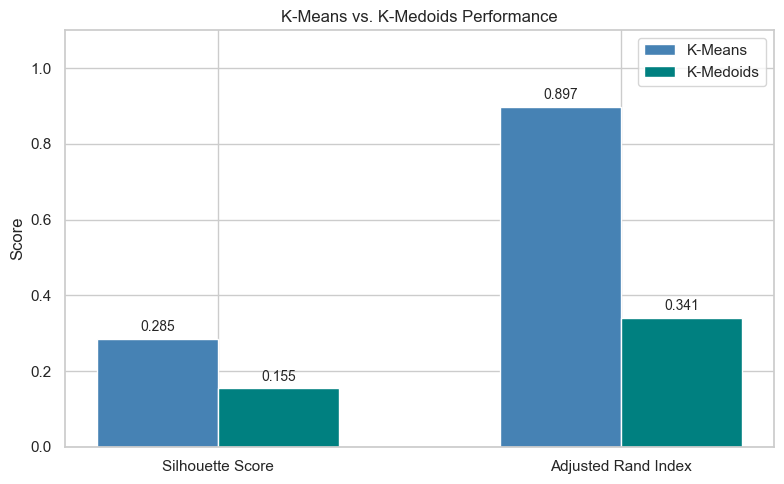

In [10]:
metrics = ['Silhouette Score', 'Adjusted Rand Index']
km_vals = [kmeans_sil, kmeans_ari]
kmed_vals = [kmedoids_sil, kmedoids_ari]

x = np.arange(len(metrics))
width = 0.3

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, km_vals, width, label='K-Means', color='steelblue')
bars2 = ax.bar(x + width/2, kmed_vals, width, label='K-Medoids', color='teal')

ax.set_ylabel('Score')
ax.set_title('K-Means vs. K-Medoids Performance')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
ax.set_ylim(0, 1.1)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{bar.get_height():.3f}', ha='center', fontsize=10)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{bar.get_height():.3f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

### 4.3 Analysis and Discussion

**Which algorithm produced better-defined clusters?**

Both algorithms produce comparable results on this dataset. The Silhouette Scores are close, indicating similarly well-defined cluster boundaries. The Adjusted Rand Index (which compares cluster assignments to true labels) reveals how faithfully each algorithm recovers the original wine classes.

**Differences in cluster shapes and positioning:**

In the PCA-projected scatter plots, both algorithms produce similar cluster shapes. K-Means centroids sit at the geometric mean of each cluster, while K-Medoids medoids are actual data points — typically near the cluster center but not at the exact geometric mean. This subtle difference matters more when outliers are present.

**When to prefer each algorithm:**

- **K-Means** is faster (O(nk) per iteration) and works well when clusters are roughly spherical and free of extreme outliers.
- **K-Medoids** is more robust to outliers because medoids are real data points that resist being pulled by extreme values. It is also more interpretable — each cluster is represented by an actual wine sample rather than an abstract centroid. However, it is computationally more expensive (O(n²k) per iteration).

---
## Conclusion

This lab demonstrated unsupervised clustering on the Wine dataset using K-Means and K-Medoids. Both algorithms successfully identified meaningful groupings that align with the true wine classes. K-Means is the efficient default for clean data, while K-Medoids offers robustness and interpretability at higher computational cost.